# STAT 5242/4242 HW3 Problem 5: Adversarial Examples and Robustness (20 points)

**Instructions:** Fill in code where you see `########## YOUR CODE HERE ##########`
and write your explanations in the **Your Answer Here** cells. Run the completed
notebook from top to bottom and retain your results and figures.

**Description:** A classifier can predict ordinary test images accurately and still
be sensitive to small, carefully chosen changes in its inputs. In this problem,
you will investigate this behavior using an MNIST classifier. You will derive a
one-step attack, implement an iterative attack, and measure how their effects
compare with random pixel noise.

This problem builds on neural-network training, input optimization,
and automatic differentiation. The new ingredient is **constrained optimization**:
the modified image must stay close to a particular original image.

There are **5 questions, worth 20 points total**, plus an optional extension.
The model, data preparation, and training loop are provided so that you can focus
on the new material. You do not need completed notebooks from the other problems.

## Setup: data and a baseline classifier

Use Python 3 with `torch`, `torchvision`, `numpy`, and `matplotlib` installed.
The first run downloads MNIST. Training uses 12,000 examples, validation uses
3,000 different examples, and final evaluation uses a fixed random subset of
1,000 test examples to keep computation manageable. The remaining examples are
unused. All required experiments work on a CPU; a CUDA GPU is used if available.

**Pixel convention:** Images are tensors of shape `(batch, 1, 28, 28)` with values
in $[0,1]$. Do not add the normalization transforms from earlier problems: all
perturbation budgets and clipping bounds below refer to this raw pixel scale.

The supplied network has no dropout or batch normalization, so its predictions
do not depend on random masks or other examples in the batch.

In [1]:
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 5242
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)

mnist_train = datasets.MNIST("./data", train=True, download=True,
                             transform=transforms.ToTensor())
mnist_test = datasets.MNIST("./data", train=False, download=True,
                            transform=transforms.ToTensor())

split_rng = torch.Generator().manual_seed(SEED)
train_indices = torch.randperm(len(mnist_train), generator=split_rng)
test_indices = torch.randperm(len(mnist_test), generator=split_rng)[:1000]
train_data = Subset(mnist_train, train_indices[:12000].tolist())
val_data = Subset(mnist_train, train_indices[12000:15000].tolist())
test_data = Subset(mnist_test, test_indices.tolist())

train_loader = DataLoader(train_data, batch_size=128, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_data, batch_size=256, shuffle=False)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)
print("Train / validation / test:", len(train_data), len(val_data), len(test_data))

PyTorch: 2.14.1+cu130 | device: cuda
Train / validation / test: 12000 3000 1000


In [2]:
class DigitNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.layers(x)  # logits, not probabilities


@torch.no_grad()
def clean_metrics(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.numel()
    return loss_sum / total, correct / total


model = DigitNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
best_val_loss = float("inf")
best_state = None

for epoch in range(5):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
    val_loss, val_acc = clean_metrics(model, val_loader)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch + 1}: validation loss={val_loss:.4f}, accuracy={val_acc:.3f}")

model.load_state_dict(best_state)
model.eval()
model.zero_grad(set_to_none=True)
print("Selected the checkpoint with the lowest validation loss.")

Epoch 1: validation loss=0.3916, accuracy=0.894


Epoch 2: validation loss=0.3108, accuracy=0.916


Epoch 3: validation loss=0.2784, accuracy=0.923


Epoch 4: validation loss=0.2594, accuracy=0.926


Epoch 5: validation loss=0.2409, accuracy=0.930
Selected the checkpoint with the lowest validation loss.


## Threat model and notation

Let $f_\theta(x)\in\mathbb{R}^{10}$ be the logits of the trained classifier, let
$y$ be the true label, and let
$\ell(f_\theta(x),y)$ be cross-entropy loss. The weights $\theta$ stay fixed during
an attack. We allow the attacker to use the model, its input gradients, and the
true label. The goal is **untargeted**: induce any incorrect prediction.

For an original image $x\in[0,1]^{784}$ and a budget $\epsilon\geq 0$, define

$$\mathcal{S}_\epsilon(x)=
\{z\in[0,1]^{784}:\|z-x\|_\infty\leq\epsilon\},
\qquad \|v\|_\infty=\max_j |v_j|.$$

We search for a high-loss image in this set:

$$x_{\mathrm{adv}}\approx
\underset{z\in\mathcal{S}_\epsilon(x)}{\operatorname{arg\,max}}
\ell(f_\theta(z),y).$$

Increasing cross-entropy is a useful surrogate for causing misclassification;
these two events are not equivalent. A pixel bound also does not guarantee
that an image looks unchanged or retains its original human label.

## Question 1: Derive a one-step attack (3 points)

Write $g=\nabla_x\ell(f_\theta(x),y)$ and use the first-order approximation

$$\ell(f_\theta(x+\delta),y)\approx
\ell(f_\theta(x),y)+g^T\delta.$$

1. Temporarily ignore the pixel bounds. Solve
   $\max_{\|\delta\|_\infty\leq\epsilon}g^T\delta$ coordinate by coordinate.
   Give one maximizing $\delta$ and the maximum value in terms of $\|g\|_1$.
   Explain what happens when $g_j=0$. **(1 point)**
2. Restore the pixel bounds. Show that coordinatewise clipping of the resulting
   $x+\delta$ to $[0,1]$ still maximizes this **linearized** objective over
   $\mathcal{S}_\epsilon(x)$. **(1 point)**
3. Does this also find a global maximizer of the original neural-network loss?
   Explain in one or two sentences. **(1 point)**

**Your Answer Here:**

1. The objective separates by coordinate. A maximizer is $\delta_j=\epsilon\operatorname{sign}(g_j)$, giving $\max g^T\delta=\epsilon\sum_j|g_j|=\epsilon\|g\|_1$. If $g_j=0$, every $\delta_j\in[-\epsilon,\epsilon]$ gives the same contribution.

2. With pixel bounds, each feasible coordinate lies in $[\max(0,x_j-\epsilon),\min(1,x_j+\epsilon)]$. A positive $g_j$ selects the upper endpoint and a negative $g_j$ the lower endpoint; either endpoint is obtained by clipping $x_j+\epsilon\operatorname{sign}(g_j)$ to $[0,1]$. For $g_j=0$ every feasible value is optimal.

3. This solves the linear approximation, not necessarily the nonlinear neural-network loss. The gradient can change away from $x$, so a global maximum of the original loss need not occur at this point.

## Question 2: Fast Gradient Sign Method (4 points)

Implement `fgsm_attack` using your result from Question 1. Compute the gradient
with respect to the **input**, take one step of size `epsilon` in the appropriate
sign direction, and enforce the valid pixel range.

Requirements:

- Use true labels and `F.cross_entropy` on logits.
- Use `torch.autograd.grad` to obtain the input gradient without accumulating
  parameter gradients. Do not call an optimizer or modify model weights.
- Create a detached copy of the input with `requires_grad_(True)`. Return a
  detached tensor and do not change the caller's input in place.
- Use evaluation mode. The forward pass used to construct the attack must
  still track gradients; `model.eval()` and `torch.no_grad()` do different things.

**Grading:** input gradients (1), update and clipping (2), correct gradient and
tensor handling (1).

In [3]:
def fgsm_attack(model, x, y, epsilon):
    """Return adversarial images with the same shape, dtype, and device as x."""
    model.eval()
    ########## YOUR CODE HERE ##########
    x_input = x.detach().clone().requires_grad_(True)
    loss = F.cross_entropy(model(x_input), y)
    grad = torch.autograd.grad(loss, x_input)[0]
    return (x_input + epsilon * grad.sign()).clamp(0, 1).detach()
    ##################################

In [4]:
# Use validation data for implementation checks, before final test evaluation.
x_check, y_check = next(iter(val_loader))
x_check, y_check = x_check[:16].to(device), y_check[:16].to(device)
x_original = x_check.clone()
weights_before = {name: p.detach().clone() for name, p in model.named_parameters()}


def check_feasible(x_adv, x, epsilon):
    assert x_adv.shape == x.shape
    assert x_adv.device == x.device and x_adv.dtype == x.dtype
    assert torch.isfinite(x_adv).all()
    assert not x_adv.requires_grad
    assert x_adv.min().item() >= -1e-6 and x_adv.max().item() <= 1 + 1e-6
    per_image_distance = (x_adv - x).flatten(1).abs().amax(dim=1)
    assert (per_image_distance <= epsilon + 1e-6).all()


model.zero_grad(set_to_none=True)
assert torch.allclose(fgsm_attack(model, x_check, y_check, 0.0), x_check)
x_fgsm = fgsm_attack(model, x_check, y_check, 0.1)
check_feasible(x_fgsm, x_check, 0.1)
assert torch.equal(x_check, x_original)
assert all(torch.equal(p, weights_before[name]) for name, p in model.named_parameters())
assert all(p.grad is None for p in model.parameters())
print("FGSM constraint and gradient-handling checks passed.")
# These checks verify basic properties; they do not prove that an attack is effective.

FGSM constraint and gradient-handling checks passed.


## Question 3: Projected gradient ascent (5 points)

A one-step approximation may miss useful directions when the gradient changes
along the path. Implement the iterative method commonly called **PGD** in
adversarial robustness; here its inner attack performs gradient **ascent**.

Starting from $x^{(0)}$, repeat for $t=0,\ldots,T-1$:

$$u^{(t+1)}=x^{(t)}+\alpha\,\operatorname{sign}
\left(\nabla_{x^{(t)}}\ell(f_\theta(x^{(t)}),y)\right),$$
$$x^{(t+1)}=\Pi_{\mathcal{S}_\epsilon(x)}(u^{(t+1)}).$$

1. Derive the coordinatewise formula for the Euclidean projection
   $\Pi_{\mathcal{S}_\epsilon(x)}(u)$, including the pixel bounds. Explain why
   the feasible interval is centered on the **original** $x$, not the latest
   iterate. **(1 point)**
2. Implement `pgd_attack`. For a random start, draw independent pixel noise from
   $\mathrm{Uniform}[-\epsilon,\epsilon]$, add it to $x$, and clip to $[0,1]$.
   This gives a feasible start; after clipping, it is not generally uniform over
   the feasible set. For `random_start=False`, start at $x$. At each iteration,
   detach the current image, enable its gradients, take a sign-gradient step,
   and project back into $\mathcal{S}_\epsilon(x)$. Return the final detached
   iterate. **(3 points)**
3. Verify numerically that one iteration with `random_start=False` and
   `alpha=epsilon` agrees with FGSM. Explain why the two updates coincide.
   **(1 point)**

Use `torch.autograd.grad`. Keep model weights fixed and do not accumulate
parameter gradients. Use `steps=10` and `alpha=epsilon/4` in the main experiment.

**Your Answer Here (parts 1 and 3):**

1. The projection is coordinatewise clipping to the intersection of the pixel range and the original image's $\epsilon$-ball:

$$
[\Pi_{\mathcal S_\epsilon(x)}(u)]_j = \min\{\min(1,x_j+\epsilon),\max(\max(0,x_j-\epsilon),u_j)\}.
$$

Squared Euclidean distance is separable, so each coordinate's closest feasible value is its clipped value. The interval is centered on the original $x$ because the threat model bounds total displacement from that image; centering on each latest iterate could allow the total displacement to exceed $\epsilon$.

3. One step without a random start uses the same input gradient and sign update as FGSM. With $\alpha=\epsilon$, projection reduces to clipping the FGSM update to the pixel range. The numerical check below verifies this.

In [5]:
def pgd_attack(model, x, y, epsilon, alpha, steps=10, random_start=True):
    """Return the final iterate of one PGD run; x is the fixed reference image."""
    model.eval()
    ########## YOUR CODE HERE ##########
    original = x.detach().clone()
    lower = (original - epsilon).clamp(0, 1)
    upper = (original + epsilon).clamp(0, 1)
    if random_start:
        current = (original + torch.empty_like(original).uniform_(-epsilon, epsilon)).clamp(0, 1)
    else:
        current = original.clone()
    for _ in range(steps):
        current = current.detach().requires_grad_(True)
        loss = F.cross_entropy(model(current), y)
        grad = torch.autograd.grad(loss, current)[0]
        current = current.detach() + alpha * grad.sign()
        current = torch.maximum(torch.minimum(current, upper), lower)
    return current.detach()
    ##################################

In [6]:
model.zero_grad(set_to_none=True)
x_pgd = pgd_attack(model, x_check, y_check, epsilon=0.1, alpha=0.025)
check_feasible(x_pgd, x_check, 0.1)
assert torch.allclose(
    pgd_attack(model, x_check, y_check, epsilon=0.0, alpha=0.0), x_check
)
assert torch.equal(x_check, x_original)
assert all(torch.equal(p, weights_before[name]) for name, p in model.named_parameters())
assert all(p.grad is None for p in model.parameters())

########## YOUR CODE HERE ##########
# Compare one-step PGD (no random start, alpha=epsilon=0.1) with FGSM.
# Use torch.allclose(..., atol=1e-6) and print the maximum absolute difference.
one_step = pgd_attack(model, x_check, y_check, epsilon=0.1, alpha=0.1, steps=1, random_start=False)
fgsm_one = fgsm_attack(model, x_check, y_check, 0.1)
max_difference = (one_step - fgsm_one).abs().max().item()
print(f"One-step maximum absolute difference: {max_difference:.9g}")
assert torch.allclose(one_step, fgsm_one, atol=1e-6)
##################################

One-step maximum absolute difference: 0


## Question 4: Evaluate and visualize robustness (4 points)

Use the same fixed test subset for every method and each budget
$\epsilon\in\{0,0.05,0.10,0.20,0.30\}$. Use **three independent random starts**
for PGD at each nonzero budget. Freeze the model and all settings before final
test evaluation; use validation data if you need to debug or explore settings.

An attack can sometimes correct an image that was initially misclassified.
To avoid counting this as robustness, define **survival** explicitly. For each
test example $i$, let $C_i$ indicate a correct clean prediction, $F_i$ a correct
prediction on its FGSM image, and $P_{ir}$ a correct prediction on the final
PGD image from restart $r$.

Report the following fractions using **all $N$ test examples** as the denominator:

| Metric | Definition |
|:--|:--|
| Clean accuracy | $N^{-1}\sum_i C_i$ |
| Random-noise accuracy | Accuracy after one independent uniform perturbation per image, clipped to $[0,1]$ |
| FGSM survival | $N^{-1}\sum_i C_iF_i$ |
| PGD survival | $N^{-1}\sum_i C_i\prod_{r=1}^{3}P_{ir}$ |
| Combined survival | $N^{-1}\sum_i C_iF_i\prod_{r=1}^{3}P_{ir}$ |

PGD survival here checks the **final** iterate of each restart. It does not check
every intermediate iterate. A more exhaustive search could find further failures.

1. Complete `evaluate_attacks`, keeping a Boolean mask for each example. A PGD
   failure in any restart must remain a failure when later restarts are combined.
   Also return the combined attack success rate **among initially correct
   examples**: $(\sum_i C_i-\sum_i C_iF_i\prod_rP_{ir})/\sum_i C_i$.
   Return `NaN` if its denominator is zero. **(2 points)**
2. Run the supplied table and plot cells. Check that all five metrics equal
   clean accuracy at $\epsilon=0$, and that combined survival is no greater than
   either FGSM or PGD survival. **(1 point)**
3. For the first five initially correct images in the fixed test order, show
   three columns: original, actual signed perturbation, and PGD image, at
   $\epsilon=0.20$. Use the same color scale for every perturbation; label it
   clearly. Show true and predicted labels, and report each image's actual
   $L_\infty$ perturbation norm. Keep all five examples even if an attack fails.
   **(1 point)**

In [7]:
def evaluate_attacks(model, loader, epsilon, steps=10, restarts=3):
    model.eval()
    counts = dict(clean=0, random_noise=0, fgsm=0, pgd=0, combined=0)
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            clean_ok = model(x).argmax(dim=1).eq(y)
            noise = torch.empty_like(x).uniform_(-epsilon, epsilon)
            x_noise = (x + noise).clamp(0, 1)
            noise_ok = model(x_noise).argmax(dim=1).eq(y)

        ########## YOUR CODE HERE ##########
        # Generate FGSM images with gradients enabled; evaluate their labels
        # under no_grad. Define fgsm_ok to include clean_ok.
        # Start pgd_ok from clean_ok.clone(). For each independent PGD call,
        # combine its correctness mask with pgd_ok using logical AND.
        # Set combined_ok to the intersection of fgsm_ok and pgd_ok.
        x_fgsm_batch = fgsm_attack(model, x, y, epsilon)
        with torch.no_grad():
            fgsm_ok = clean_ok & model(x_fgsm_batch).argmax(dim=1).eq(y)
        pgd_ok = clean_ok.clone()
        for _ in range(restarts):
            x_pgd_batch = pgd_attack(model, x, y, epsilon, alpha=epsilon / 4, steps=steps)
            with torch.no_grad():
                pgd_ok &= model(x_pgd_batch).argmax(dim=1).eq(y)
        combined_ok = fgsm_ok & pgd_ok
        ##################################

        counts["clean"] += clean_ok.sum().item()
        counts["random_noise"] += noise_ok.sum().item()
        counts["fgsm"] += fgsm_ok.sum().item()
        counts["pgd"] += pgd_ok.sum().item()
        counts["combined"] += combined_ok.sum().item()
        total += y.numel()

    rates = {name: count / total for name, count in counts.items()}
    ########## YOUR CODE HERE ##########
    # Add rates["attack_success"] with the conditional denominator above.
    rates["attack_success"] = ((counts["clean"] - counts["combined"]) / counts["clean"]
                               if counts["clean"] else float("nan"))
    ##################################
    return rates

In [8]:
# Run after Questions 2-4 are complete. Do not tune on these test results.
torch.manual_seed(SEED + 1)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED + 1)

epsilons = [0.0, 0.05, 0.10, 0.20, 0.30]
results = [evaluate_attacks(model, test_loader, eps) for eps in epsilons]

print("Rates are fractions. FGSM / PGD / combined columns report survival.")
print(f"{'eps':>5} {'clean':>8} {'noise':>8} {'FGSM':>8} {'PGD':>8} {'combined':>10} {'success*':>10}")
for eps, row in zip(epsilons, results):
    print(f"{eps:5.2f} {row['clean']:8.3f} {row['random_noise']:8.3f} "
          f"{row['fgsm']:8.3f} {row['pgd']:8.3f} {row['combined']:10.3f} "
          f"{row['attack_success']:10.3f}")
print("*Attack success is conditional on a correct clean prediction.")

for key in ["clean", "random_noise", "fgsm", "pgd", "combined"]:
    assert abs(results[0][key] - results[0]["clean"]) < 1e-12
for row in results:
    assert row["combined"] <= min(row["fgsm"], row["pgd"]) + 1e-12
    assert max(row["fgsm"], row["pgd"]) <= row["clean"] + 1e-12
print("Evaluation consistency checks passed.")

Rates are fractions. FGSM / PGD / combined columns report survival.
  eps    clean    noise     FGSM      PGD   combined   success*
 0.00    0.929    0.929    0.929    0.929      0.929      0.000
 0.05    0.929    0.929    0.584    0.533      0.532      0.427
 0.10    0.929    0.926    0.112    0.065      0.065      0.930
 0.20    0.929    0.894    0.000    0.000      0.000      1.000
 0.30    0.929    0.841    0.000    0.000      0.000      1.000
*Attack success is conditional on a correct clean prediction.
Evaluation consistency checks passed.


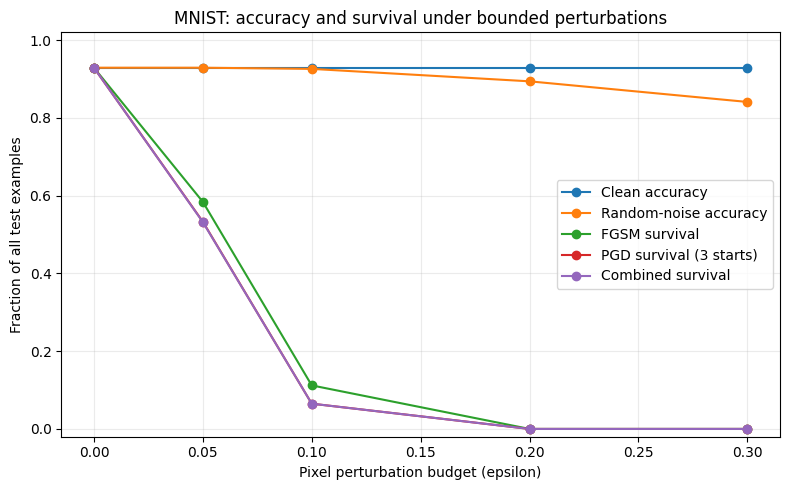

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for key, label in [("clean", "Clean accuracy"),
                   ("random_noise", "Random-noise accuracy"),
                   ("fgsm", "FGSM survival"),
                   ("pgd", "PGD survival (3 starts)"),
                   ("combined", "Combined survival")]:
    ax.plot(epsilons, [row[key] for row in results], marker="o", label=label)
ax.set(xlabel="Pixel perturbation budget (epsilon)",
       ylabel="Fraction of all test examples", ylim=(-0.02, 1.02),
       title="MNIST: accuracy and survival under bounded perturbations")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

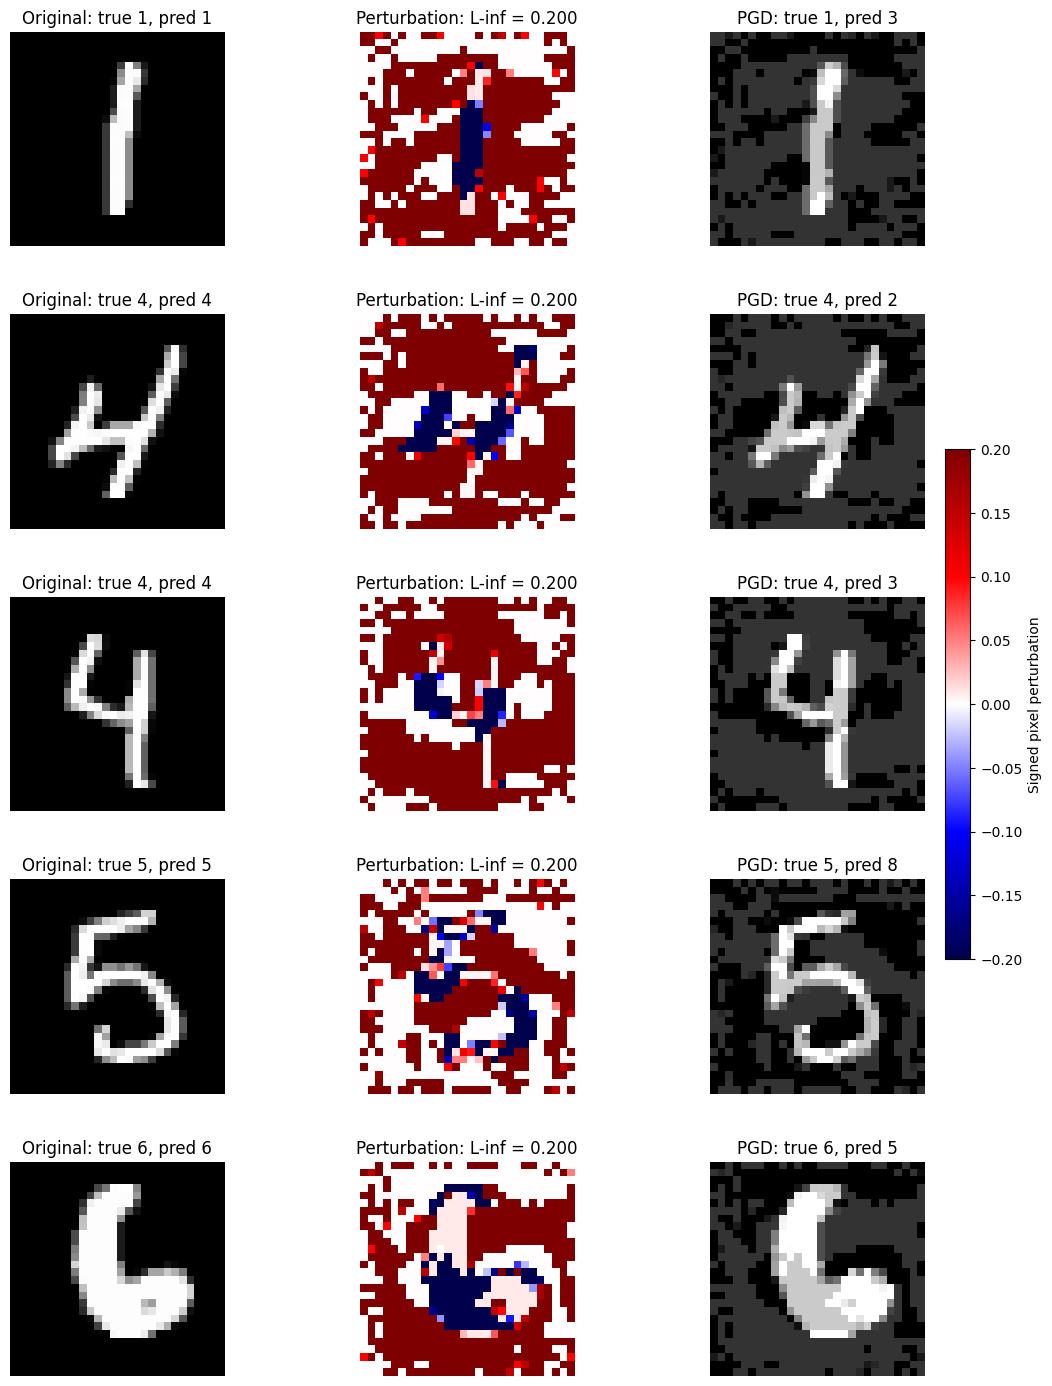

In [10]:
# Select the first five clean-correct examples without selecting for attack success.
selected_x, selected_y = [], []
model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        keep = model(x).argmax(dim=1).eq(y)
        selected_x.extend(x[keep].split(1))
        selected_y.extend(y[keep].split(1))
        if len(selected_x) >= 5:
            break
assert len(selected_x) >= 5, "Inspect the baseline if fewer than five images are correct."
x_show = torch.cat(selected_x[:5])
y_show = torch.cat(selected_y[:5])

########## YOUR CODE HERE ##########
# Generate one random-start, 10-step PGD image for each selected original.
# Use epsilon=0.20 and alpha=0.05. Compute delta = x_adv - x_show.
# Plot 5 rows by 3 columns. For original/adversarial images use
# cmap="gray", vmin=0, vmax=1. For signed delta use cmap="seismic",
# vmin=-0.20, vmax=0.20 and a labeled colorbar.
# Include the true/predicted labels and each actual infinity norm.
x_adv_show = pgd_attack(model, x_show, y_show, epsilon=0.20, alpha=0.05, steps=10)
delta = x_adv_show - x_show
with torch.no_grad():
    original_pred = model(x_show).argmax(dim=1).cpu()
    adv_pred = model(x_adv_show).argmax(dim=1).cpu()
fig, axes = plt.subplots(5, 3, figsize=(12, 14))
for i in range(5):
    norm = delta[i].abs().max().item()
    axes[i, 0].imshow(x_show[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Original: true {y_show[i].item()}, pred {original_pred[i].item()}")
    image_delta = axes[i, 1].imshow(delta[i, 0].detach().cpu(), cmap="seismic", vmin=-0.20, vmax=0.20)
    axes[i, 1].set_title(f"Perturbation: L-inf = {norm:.3f}")
    axes[i, 2].imshow(x_adv_show[i, 0].detach().cpu(), cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(f"PGD: true {y_show[i].item()}, pred {adv_pred[i].item()}")
    for ax in axes[i]:
        ax.axis("off")
fig.subplots_adjust(left=0.03, right=0.88, bottom=0.02, top=0.98, wspace=0.28, hspace=0.32)
cbar = fig.colorbar(image_delta, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02)
cbar.set_label("Signed pixel perturbation")
plt.show()
##################################

## Question 5: Interpret the experiment (4 points)

Answer each part in two to four sentences, referring to your measurements where
appropriate. Unexpected results are acceptable if you investigate and explain them.

For the comparison below, consider this simple version of **Deep Dream**: keep a trained network fixed, start from a random image, and optimize the image to maximize a selected output neuron's activation, without a perturbation constraint around a given original image. You do not need to complete a separate Deep Dream notebook.

1. **Input optimization:** Compare this attack with Deep Dream. What is optimized
   in each case, what stays fixed, and how do their objectives, starting images,
   and constraints differ? **(1 point)**
2. **Direction matters:** How did random noise compare with gradient-based
   perturbations at the same $\epsilon$? Use your first-order analysis to explain
   why matching the pixel budget does not imply matching the effect on loss.
   Comment on whether the displayed changes are visible. **(1 point)**
3. **What was measured:** Define true empirical robust accuracy on this fixed test
   subset as the fraction correctly classified at **every** point in
   $\mathcal{S}_\epsilon(x_i)$. Is combined survival an upper bound or a lower
   bound on this quantity? Justify the direction. Does failure to find an
   adversarial example prove one does not exist? **(1 point)**
4. **Optimization limits:** Must finite-step PGD always outperform FGSM? Must
   measured survival decrease monotonically as $\epsilon$ increases? Distinguish
   these heuristic measurements from the true empirical robust accuracy, whose
   feasible perturbation sets are nested. **(1 point)**

**Your Answer Here:**

1. Both methods optimize the input while keeping the trained model fixed. Here the attack starts from a particular test image and maximizes cross-entropy with its true label subject to a bounded perturbation and valid pixels. In the stated Deep Dream setup, optimization starts from a random image and maximizes a selected neuron's activation without a constraint around an original image.

2. At $\epsilon=0.10$, random-noise accuracy was 0.926, while FGSM and three-start PGD survival were 0.112 and 0.065, respectively (the latter are restricted to clean-correct images). The first-order loss change is $g^T\delta$: the sign-gradient step aligns coordinates with $g$ instead of allowing positive and negative contributions to cancel as random noise may. In the displayed $\epsilon=0.20$ examples, the changes are visibly apparent, especially in the background.

3. Combined survival is an **upper bound** on true empirical robust accuracy: an image correct at every feasible point must survive all tested attacks, but survival of finitely many attack outputs does not establish correctness everywhere. Therefore failure to find an adversarial example does not prove that none exists.

4. Finite-step PGD need not outperform FGSM: its starting point, step size, trajectory and final-iterate selection may miss a failure found by FGSM. Measured survival need not decrease monotonically with budget because these heuristic searches and random starts can yield different outcomes. True empirical robust accuracy is nonincreasing as $\epsilon$ increases because the feasible sets are nested.


## Optional extension: Can training improve robustness? (ungraded)

Starting from two copies of the same selected baseline checkpoint, compare three
additional epochs of ordinary training with three epochs of adversarial training.
Create fresh Adam optimizers with the same learning rate $10^{-3}$ and use the
same training examples and minibatch order for both branches. For the adversarial
branch, generate fresh five-step PGD images for each training batch using the
current weights, with $\epsilon_{\mathrm{train}}=0.10$ and $\alpha=0.025$.
Then take a parameter update using

$$L_{\mathrm{mix}}(\theta)=\tfrac12\ell(f_\theta(x),y)
+\tfrac12\ell(f_\theta(\operatorname{stopgrad}(x_{\mathrm{adv}})),y).$$

Detach adversarial inputs before the parameter update; do not differentiate
through the attack procedure. Generate attacks in evaluation mode, then restore
training mode for the weight update. Never train on validation or test examples.

Choose any changes using validation data. If you complete this extension, fix
both training procedures before comparing them on the test subset. Evaluate both
models with the same Question 4 attack settings, generating new attacks against
each model's own weights. Compare clean accuracy and combined survival. Explain
why equal numbers of additional training epochs provide a useful control, while
not implying equal computational cost, and why these results do not establish
robustness against every possible attack.

## References and useful documentation

The problem combines the course's MNIST, input-gradient, and optimization themes
in a new exercise. These resources provide background; the notebook above is
self-contained.

- [PyTorch: Adversarial Example Generation (FGSM)](https://docs.pytorch.org/tutorials/beginner/fgsm_tutorial.html)
- [PyTorch: torch.autograd.grad](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html)
- [Madry et al., Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/abs/1706.06083)

**Before submitting:** Include the written derivations, completed attack functions,
consistency checks, results table, robustness plot, image comparison, and reflections.
No particular numerical accuracy is required; correct methods and interpretation matter.